[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/03_descriptors_druglikeness.ipynb)

# 03 · Molecular Descriptors and Drug-Likeness

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

Descriptors turn a structure into numbers. They are the input to QSAR models,
the basis of drug-likeness filters, and a quick way to understand what a dataset contains.
We use two real datasets: ESOL (solubility; small organics, pesticides, drugs) and a curated
set of **6,871 EGFR inhibitors** from ChEMBL 37 (medicinal-chemistry compounds).

**Learning objectives.** By the end of this notebook you will be able to:

- compute physicochemical descriptors (MW, logP, TPSA, HBD/HBA, rotatable bonds)
- apply Lipinski's Rule of Five and Veber's rules
- compute and interpret QED, the quantitative estimate of drug-likeness
- compare the property profiles of two datasets

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, Lipinski, QED, rdMolDescriptors, Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")

esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
egfr = pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv")
print("ESOL:", esol.shape, "| EGFR:", egfr.shape)
egfr.head()

ESOL: (1128, 3) | EGFR: (6871, 4)


,compound_id,smiles,p_activity,active
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,5.00,0
1,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,6.34,0
2,CHEMBL102726,c1ccc(CNc2ncnc3ccccc23)cc1,6.50,0
3,CHEMBL103552,O=C(O)c1cc(N(Cc2ccccc2O)Cc2cc(O)ccc2O)ccc1O,5.39,0
4,CHEMBL103860,O=C(O)c1cc(CCc2cc(O)ccc2O)ccc1O,5.48,0


In the EGFR table, `p_activity` is the pIC50 (−log10 of the IC50 in mol/L; 6 = 1 µM, 9 = 1 nM),
already aggregated to one value per compound.

## 1. The classic descriptors

| Descriptor | RDKit function | Why it matters |
|---|---|---|
| Molecular weight | `Descriptors.MolWt` | size; absorption drops for large molecules |
| logP (Crippen) | `Crippen.MolLogP` | lipophilicity; solubility, permeability, promiscuity |
| TPSA | `rdMolDescriptors.CalcTPSA` | polar surface; permeability, brain penetration |
| H-bond donors / acceptors | `Lipinski.NumHDonors` / `NumHAcceptors` | polarity, permeability |
| Rotatable bonds | `Lipinski.NumRotatableBonds` | flexibility; oral bioavailability |

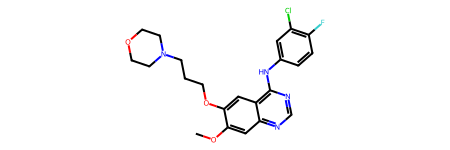

{'MW': 446.91,
 'logP': 4.28,
 'TPSA': 68.74,
 'HBD': 1,
 'HBA': 7,
 'RotB': 8,
 'QED': 0.52}

In [3]:
def describe(mol):
    return {
        "MW": Descriptors.MolWt(mol),
        "logP": Crippen.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotB": Lipinski.NumRotatableBonds(mol),
        "QED": QED.qed(mol),
    }

gefitinib = Chem.MolFromSmiles(egfr.loc[egfr.compound_id == "CHEMBL939", "smiles"].iloc[0])
display(gefitinib)
{k: round(v, 2) for k, v in describe(gefitinib).items()}

## 2. Descriptors for whole datasets

In [4]:
def descriptor_table(smiles_series):
    rows = []
    for s in smiles_series:
        m = Chem.MolFromSmiles(s)
        rows.append(describe(m) if m is not None else {})
    return pd.DataFrame(rows, index=smiles_series.index)

esol_d = pd.concat([esol, descriptor_table(esol["smiles"])], axis=1)
egfr_d = pd.concat([egfr, descriptor_table(egfr["smiles"])], axis=1)
egfr_d[["MW", "logP", "TPSA", "HBD", "HBA", "RotB", "QED"]].describe().round(2)

,MW,logP,TPSA,HBD,HBA,RotB,QED
count,6871.00,6871.00,6871.00,6871.00,6871.00,6871.00,6871.00
mean,499.23,4.70,99.70,2.29,7.09,7.33,0.37
std,118.99,1.39,30.14,1.23,2.14,3.18,0.18
min,174.59,-0.83,15.60,0.00,1.00,0.00,0.02
25%,425.49,3.81,80.05,1.00,6.00,5.00,0.22
50%,496.62,4.62,100.44,2.00,7.00,7.00,0.35
75%,567.49,5.55,115.66,3.00,8.00,9.00,0.50
max,1425.80,13.12,302.28,11.00,19.00,36.00,0.94


## 3. Lipinski's Rule of Five

An orally active drug usually has **no more than one** violation of: MW ≤ 500, logP ≤ 5, HBD ≤ 5, HBA ≤ 10.
It is a rule of thumb from 1997, not a law. Many approved drugs break it.

In [5]:
def lipinski_violations(row):
    return int(row.MW > 500) + int(row.logP > 5) + int(row.HBD > 5) + int(row.HBA > 10)

for name, df in [("ESOL", esol_d), ("EGFR", egfr_d)]:
    df["Ro5_violations"] = df.apply(lipinski_violations, axis=1)
    passed = (df["Ro5_violations"] <= 1).mean()
    print(f"{name}: {passed:.1%} pass Ro5 (≤1 violation)")
    print(df["Ro5_violations"].value_counts().sort_index().to_string(), "\n")

ESOL: 98.9% pass Ro5 (≤1 violation)
Ro5_violations
0    1018
1      98
2      10
3       2 

EGFR: 68.6% pass Ro5 (≤1 violation)
Ro5_violations
0    2889
1    1826
2    2022
3     128
4       6 



## 4. QED: a smooth drug-likeness score

Hard cut-offs throw away borderline molecules. **QED** (Bickerton *et al.*, *Nat. Chem.* 2012)
combines eight properties into a single desirability score between 0 (unlike known drugs) and 1.

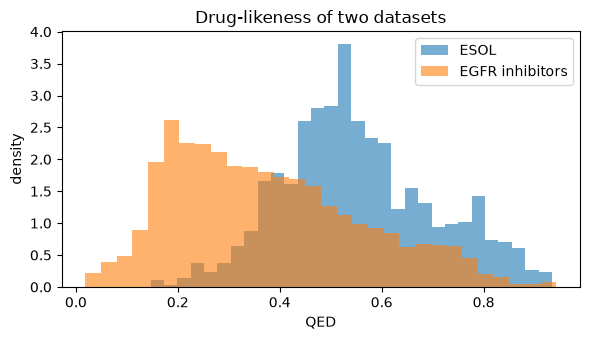

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(esol_d["QED"], bins=30, alpha=0.6, density=True, label="ESOL")
ax.hist(egfr_d["QED"], bins=30, alpha=0.6, density=True, label="EGFR inhibitors")
ax.set_xlabel("QED"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Drug-likeness of two datasets")
plt.tight_layout(); plt.show()

## 5. Comparing property profiles

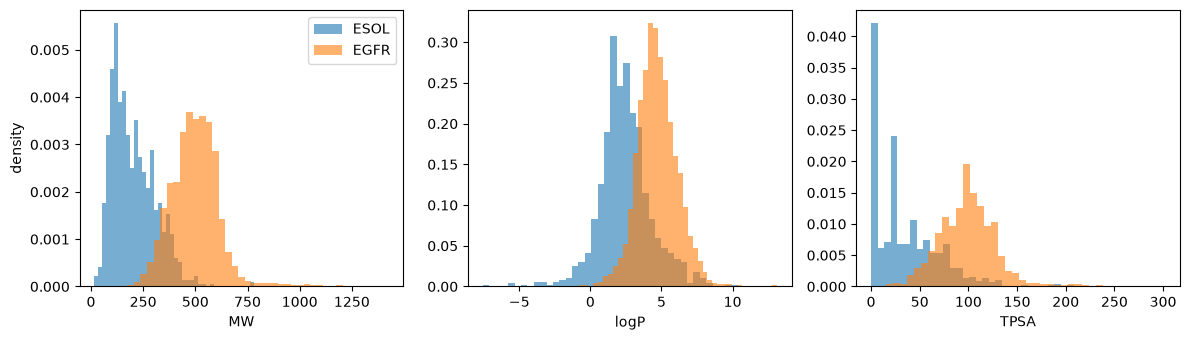

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ["MW", "logP", "TPSA"]):
    ax.hist(esol_d[col], bins=40, alpha=0.6, density=True, label="ESOL")
    ax.hist(egfr_d[col], bins=40, alpha=0.6, density=True, label="EGFR")
    ax.set_xlabel(col)
axes[0].set_ylabel("density"); axes[0].legend()
plt.tight_layout(); plt.show()

The EGFR inhibitors are larger and more polar than the ESOL compounds: typical of
kinase-inhibitor medicinal chemistry, compared with the small organics and pesticides in ESOL.
A model trained on one would be extrapolating badly on the other. Keep this in mind for Notebook 08.

## 6. Descriptors explain properties: logP vs solubility

Lipophilic compounds tend to be poorly soluble. Delaney's ESOL equation is built on exactly this idea.

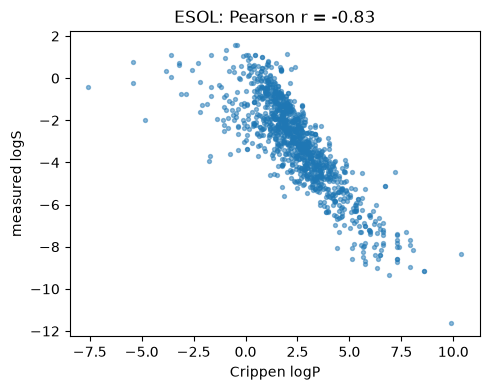

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(esol_d["logP"], esol_d["logS"], s=8, alpha=0.5)
ax.set_xlabel("Crippen logP"); ax.set_ylabel("measured logS")
r = esol_d[["logP", "logS"]].corr().iloc[0, 1]
ax.set_title(f"ESOL: Pearson r = {r:.2f}")
plt.tight_layout(); plt.show()

## 7. All RDKit descriptors at once

`Descriptors.CalcMolDescriptors` returns ~200 descriptors. Useful as model features (Notebook 10).

In [9]:
all_desc = Descriptors.CalcMolDescriptors(gefitinib)
print(len(all_desc), "descriptors, e.g.:")
pd.Series(all_desc).head(10)

217 descriptors, e.g.:


MaxAbsEStateIndex       13.468244
MaxEStateIndex          13.468244
MinAbsEStateIndex        0.036409
MinEStateIndex          -0.474756
qed                      0.517855
SPS                     14.548387
MolWt                  446.910000
HeavyAtomMolWt         422.718000
ExactMolWt             446.152097
NumValenceElectrons    164.000000
dtype: float64

### ✏️ Exercise 1

Veber's rules for oral bioavailability: rotatable bonds ≤ 10 **and** TPSA ≤ 140 Å². What fraction of the EGFR compounds pass?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
veber = (egfr_d["RotB"] <= 10) & (egfr_d["TPSA"] <= 140)
print(f"{veber.mean():.1%} of EGFR compounds pass Veber's rules")
```

</details>

### ✏️ Exercise 2

Draw the 6 EGFR compounds with the highest QED, with their QED and pIC50 as legends.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
top = egfr_d.nlargest(6, "QED")
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in top["smiles"]], molsPerRow=3,
                     subImgSize=(250, 200),
                     legends=[f"QED={q:.2f}  pIC50={p}" for q, p in zip(top["QED"], top["p_activity"])])
```

</details>

### ✏️ Exercise 3

Is potency related to size? Compute the Spearman correlation between `MW` and `p_activity` in the EGFR set.

*Hint:* `DataFrame.corr(method='spearman')`.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
rho = egfr_d[["MW", "p_activity"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rho(MW, pIC50) = {rho:.2f}")
```

</details>

## Key takeaways

- A handful of descriptors (MW, logP, TPSA, HBD, HBA, RotB) summarize what a compound set looks like.
- Rule-of-five style filters are quick heuristics; QED gives a continuous score.
- Comparing descriptor distributions reveals when two datasets cover different chemistry.

**Next:** [04 · Fingerprints and similarity](04_fingerprints_similarity.ipynb).